# 뉴스 감성 → 수익률 실습 결과 정리

## 1. 실습 개요

AI 데이터 인텔리전스 강의의 텍스트 모델링 실습을 투자 전략 관점으로 재구성해 세 단계로 진행했다. 모델은 모두 `klue/bert-base`이며, Colab T4 GPU 환경에서 실행했다.

* **2**: 사람이 라벨링한 금융 문장으로 종목별 감성 모델을 구축한다.
* **3**: 실제 뉴스 제목에 다음 거래일 초과수익률을 라벨로 매겨 수익률 예측 모델을 학습시킨다.
* **4**: 시장을 주도한 삼성전자·SK하이닉스에 집중해 감성 점수가 다음 거래일 시장 방향(시장 타이밍)과 두 종목 수익률 차이(페어)를 예측하는지 평가한다.

## 2. 금융 감성분석

데이터는 KorFin-ASC 8,818건(고유 문장 6,104개)을 활용했다. 동일한 문장이 종목만 바뀌어 반복 등장하므로 문장 단위로 묶어 학습 7,011건, 테스트 1,807건으로 분할했고 두 집합 간 중복 문장이 없음을 확인했다. 입력은 `[CLS] 문장 [SEP] 종목명 [SEP]` 형식의 문장쌍이며 라벨은 부정·중립·긍정 3분류다.

성능은 정확도 84.1%, Macro-F1 0.834를 기록했다.

| 클래스 | 정밀도 | 재현율 | F1 |
| --- | --- | --- | --- |
| 부정 | 0.884 | 0.904 | 0.894 |
| 중립 | 0.824 | 0.681 | 0.746 |
| 긍정 | 0.815 | 0.914 | 0.862 |

부정과 긍정은 원활히 구분하나 중립 판정이 약하다. 실제 중립 문장의 32%가 긍정이나 부정으로 분류되었다. 긍정 재현율이 높고 정밀도가 낮아 모델이 긍정 편향을 띤다. 신호 부호를 뒤집는 방향 반전 오답(긍정↔부정)은 36건(1.99%)이었다.

학습 손실은 0.51 → 0.15로 꾸준히 감소했으나 검증 손실은 2에폭 이후 0.445 → 0.489로 상승해 과적합이 관찰되었으며, F1 기준 2에폭 모델을 최종 선택했다. 확신도 0.9 이상에서 발생한 오답이 전체 오답의 34%를 차지해 확률값을 그대로 포지션 크기에 적용하기는 어렵다. 문장 길이에 따라서는 60～100자 문장의 정확도가 가장 높았고(88.8%), 150～250자 문장이 가장 낮았다(75.9%).

문장쌍 설계는 의도대로 작용했다. "삼성전자의 HBM 공급 확대로 SK하이닉스의 점유율 하락이 우려된다"는 문장은 SK하이닉스 기준 부정(0.993), 삼성전자 기준 중립(0.918)으로 분류되었다.

## 3. 뉴스 → 다음 거래일 초과수익률 분류

### 데이터

빅카인즈에서 매일경제 기사 1년 치(2025-10-23～2026-10-23) 7,947건을 수집했다. 중복·예외 기사를 제외한 7,671건 중 제목에 종목명(별칭 포함)이 포함된 기사는 2,386건(31%)이다. 종목 배정 후 표본은 22개 종목 3,159건이다. 삼성전자(1,988건)와 SK하이닉스(922건)가 전체의 92%를 차지하는데, 이는 데이터 결함이 아닌 당해 구간 KOSPI가 두 종목 중심으로 움직인 시장 구조를 반영한 결과다.

빅카인즈는 발행 날짜만 제공하므로 모든 기사를 장 마감 후 발행으로 정형화해 다음 거래일 종가에 진입하도록 설정했다. 라벨은 그다음 거래일까지의 KOSPI 대비 초과수익률이며, 시간순으로 학습 2,091건(168일), 검증 563건(35일), 테스트 462건(36일)으로 분할했다. 3분위 임계값(하락 ≤ −0.90%, 상승 ≥ +0.95%)은 학습 구간 데이터로만 산출했다.

### 결과: 학습되지 않음

학습 손실은 1.12 → 1.06으로 변동폭이 미미했고 검증 정확도는 3에폭 내내 34～35%로 무작위 예측 수준이었다. 테스트 정확도 40.7%는 단순 보합 예측 기준선(41.1%)을 밑돌았다. 모델은 주로 보합만 출력했고 점수(P상승 − P하락)는 0 부근 ±0.4 구간에 집적되어 제목에서 뚜렷한 근거를 도출하지 못했다.

일별 평균 대상이 2.5종목에 불과해 종목 간 비교 평가(일별 IC, 롱숏)는 성립하기 어려웠다. 또한 지수가 사실상 두 종목에 집중된 환경에서는 KOSPI 대비 초과수익률이 두 종목 간 상대 수익률로 전환되어 신호가 상쇄된다. 시장 구조에 맞춘 평가 단위 재설정이 요구되었고, 이를 Part 4에서 다루었다.

## 4. 시계열·페어 평가

### 설계

발행일 기사는 자정 전까지 전량 공개되므로 다음 거래일 시가부터 매체 진입이 가능하다. 수익률 구간은 t0 시가 → t0 종가(h0)와 t0 종가 → t0+1 종가(h1) 두 가지로 산정했다. 신호 지표는 두 종목 기사의 일간 감성 평균 S(P긍정 − P부정) 및 긍정 편향을 보정한 과거 20거래일 평균 대비 변화량 ΔS다. Part 2 감성 모델 학습에 해당 뉴스와 주가를 활용하지 않았으므로 1년 전체가 표본 외(Out-of-Sample) 평가에 해당한다.

### 데이터와 시장 환경

두 종목 관련 기사 2,899건의 감성 점수를 산출했다. 뉴스가 존재한 거래일은 241일(일평균 12.0건), 두 종목 기사가 동시 존재하는 날은 218일이었다. 평균 감성은 +0.223으로 긍정 편향이 관찰되었다.

분석 기간 시장은 변동폭이 극심했다. KOSPI는 약 4,000선에서 출발해 6월 9,000선까지 급등한 후 10월 5,300선 부근으로 조정받았으며, 일간 변동성은 시가→종가 2.4%, 종가→종가 3.3%를 기록했다. 같은 기간 KOSPI 단순 보유 수익률은 종가→종가 기준 +31%, 시가→종가 기준 −20%였다. 상승분 대부분이 장중 움직임이 아닌 밤사이 갭(Gap) 상승에서 기인했음을 나타낸다.

감성 지표는 주가 추이와 상충했다. 20일 평균 감성은 연초 0.35 수준에서 주가 상승세가 가파랐던 4～6월 중 0.05 근처까지 하락했다. 해당 시기 노조 이슈 및 성과급 관련 기사 빈도가 높았던 영향이다.

### 시장 타이밍

신호 2종과 수익률 6종을 조합한 12개 검증군의 상관계수가 모두 음수(−0.015～−0.110)를 나타냈다. 다만 t값 절댓값은 최대 1.67로 통계적 유의 기준인 2에는 미달했다. 분위별 분석에서는 감성 지수가 가장 낮았던 1분위 다음 날 KOSPI 종가→종가 수익률이 +77bp(S), +64bp(ΔS)로 최고치를 기록했다.

백테스트(ΔS > 0 매수 조건, 편도 비용 5bp 적용) 결과는 아래와 같다.

| 전략 | 적중률 | 일평균(bp, 비용 후) | 누적(비용 후) | 같은 날짜 KOSPI 보유 |
| --- | --- | --- | --- | --- |
| h0 롱/현금 | 52% | −11.8 | −26.1% | −20.1% |
| h0 롱/숏 | 51% | −17.1 | −37.7% | −20.1% |
| h1 롱/현금 | 60% | +1.6 | −3.2% | +31.1% |
| h1 롱/숏 | 50% | −14.9 | −39.1% | +31.1% |

비용 차감 후 모든 전략 성과가 단순 보유를 밑돌았다. h1 롱/현금 전략은 60%의 적중률을 기록했으나 시장 노출 비율이 51%에 그쳐 주요 상승일을 이탈하면서 누적 성과가 단순 보유 대비 34%p 하회했다. 일 변동성이 3%를 상회하는 장세에서는 적중률보다 주요 변동 일수 포착 여부가 성과를 좌우한다. 사후 과적합을 방지하고자 음의 상관 결과를 바탕으로 신호 부호를 반전시키는 재백테스트는 실시하지 않았다.

### 페어

삼성전자 감성 − SK하이닉스 감성 차이와 다음 날 두 종목 간 수익률 격차의 상관계수는 −0.047～+0.062, t값은 모두 1 미만이었다. 적중률 46～52%, 비용 차감 후 누적 수익률 −29～−61%로 유효한 신호가 발견되지 않았다.

## 5. 결과 해석: 기존 연구·실무와의 비교

241거래일간의 표본 외 평가에서 시장 타이밍과 페어 전략 모두 유의미한 신호를 산출하지 못했고, 거래비용 반영 시 단순 보유 성과를 밑돌아 알파 예측 지표로서의 한계가 명확히 확인되었다.

학계 연구 결과 역시 "언급량 증가 시 매도" 관점과 상당 부분 일치한다. 미디어의 관심을 받는 종목에 개인 자금이 집중된 후 수익률이 정체된다는 주의(attention) 효과 연구나, 비관적 보도가 유발한 단기 과매도가 이후 회복된다는 분석이 지속적으로 제시되어 왔다. LLM 기반 뉴스 매매 실험에서도 고빈도 언급 종목을 매도하는 전략의 우수성이 보고된 바 있다. 본 실습 결과도 이러한 흐름을 따른다. 12개 조합의 상관계수가 일관되게 음수를 나타냈으며, 감성 지수가 최저인 날의 이튿날 수익률이 가장 높았다. 통계적 유의성은 미달했으나 뉴스 신호를 순방향으로 추종하는 것보다 역발상 접근이 유리하다는 경향성은 선행 연구와 부합한다.

실무 영역의 위험 관리체계 역시 가격 기반 지표를 핵심으로 활용한다. 내재변동성, 실현변동성, 자산 간 상관관계 등은 이미 뉴스를 수용·반영한 가격 데이터에서 도출되므로, 뉴스 텍스트를 별도로 투입해 얻는 추가 정보량은 제한적이다. 이번 실습 결과에서도 뉴스 관련 반응은 이미 밤사이 갭 상승/하락 폭에 상쇄되어 존재했다.

뉴스 데이터가 실질적 수익으로 연결되는 예외적 영역은 해석이 아닌 처리 속도에 있다. 머신러닝이 읽을 수 있는 뉴스 피드를 밀리초(ms) 단위로 수신해 즉각 집행하는 고빈도 매매(HFT) 영역에서는 데이터 거래가 성행하나, 이는 일반 운용사나 개인 영역의 접근 범위 밖이며 문맥과 감성을 해석하는 본 실습의 접근 방식과도 성격이 다르다.

## 6. 결론

뉴스 제목의 감성 지수는 다음 거래일 수익률 예측 신호로 유효하지 않았다. 1년간 241거래일의 표본 외 평가 결과, 시장 타이밍과 페어 분석 모두 통계적으로 유의한 알파를 형성하지 못했으며, 거래비용을 차감한 모든 전략 성과가 단순 보유를 하회했다. 상관계수의 부호는 일관되게 음수였는데, 이는 악재 보도 이튿날 상승폭이 커졌음을 의미하며 미디어의 집중 조명을 받은 종목의 수익률이 정체된다는 기존 연구 결과와 맥을 같이한다.

뉴스에 대한 시장 반응은 당일 장중 및 밤사이 가격 변화에 즉각 선반영되며, 위험 관리 관점에서도 가격 지표를 상회하는 고유 정보를 제공하지 못한다. 뉴스 감성 분석은 시장 맥락을 정성적으로 이해하는 참고 자료로 활용할 수 있으나, 알파 창출이나 위험 관리를 위한 단기 매매 신호로서의 가치는 검증되지 않았다. 금융공학 관점에서 뉴스 텍스트가 실질적 유효성을 갖는 구간은 정밀한 문맥 해석이 아닌 초고속 집행 영역으로 한정된다.

## 7. 실습에서 얻은 것

예측 신호는 발견되지 않았으나, 분석 결과의 신뢰도를 담보하는 실증 절차를 엄밀히 수행했다는 점에 의의가 있다.

* **정보 누수(Data Leakage) 차단**: 동일 문장이 학습과 평가 집합에 혼재되지 않도록 문장 단위 분할을 엄격히 적용했다.
* **룩어헤드 편향(Look-ahead Bias) 방지**: 기사 발행 시각을 기준으로 실제 거래 집행이 가능한 시점부터 수익률을 계산했다.
* **시계열 분할 및 임계값 고정**: 라벨링 임계값을 학습 구간 데이터로만 산출하고 모델 에폭 선택은 검증 집합으로 한정했다.
* **시장 구조적 특성 반영**: 두 종목이 지수 향방을 좌우하는 환경을 고려해 단순 종목 간 비교에서 시계열 및 페어 평가로 분석 프레임워크를 전환했다.
* **다중 검정(Multiple Testing) 오류 경계**: 무작위 수치 기반 가짜 신호에서도 t값 −2.4가 발생함을 검증했다. 다중 조합 분석 시 단일 t값 외에도 반기별 부호 지속성과 분위별 단조성을 복합 검증해야 한다.
* **거래비용 및 보유 성과 대조**: 60%의 적중률을 기록하더라도 거래비용과 주요 상승일 이탈에 따른 기회비용을 반영하면 단순 보유 성과에 미달할 수 있음을 확인했다.

실행 전: 런타임 유형 **GPU**, 빅카인즈 엑셀(`NewsResult_*.xlsx`)을 왼쪽 📁 패널에 업로드

## 1. 환경 설정

In [ ]:
# === 라이브러리 설치 + GPU 확인 ===
!pip install -q transformers datasets accelerate finance-datareader openpyxl

import torch
if torch.cuda.is_available():
    print(f"✅ GPU: {torch.cuda.get_device_name(0)} ({torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB)")
else:
    print("⚠️ GPU 없음 — 런타임 > 런타임 유형 변경 > GPU 선택 후 다시 실행")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 kB 2.4 MB/s eta 0:00:00
✅ GPU: Tesla T4 (14.6 GB)


In [ ]:
import os
import subprocess
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns


def setup_korean_font_colab():
    """Google Colab에서 한글 폰트 설정"""

    print("===== 한글 폰트 설정 시작 =====")

    # 1) 나눔 폰트 설치
    try:
        subprocess.run(["apt-get", "update", "-qq"], check=True)
        subprocess.run(["apt-get", "install", "-y", "-qq", "fonts-nanum"], check=True)
        print("[1/4] fonts-nanum 설치 완료")
    except Exception as e:
        print(f"[1/4] fonts-nanum 설치 중 오류: {e}")

    # 2) 시스템 폰트 캐시 갱신
    try:
        subprocess.run(["fc-cache", "-fv"], check=True, stdout=subprocess.DEVNULL)
        print("[2/4] 시스템 폰트 캐시 갱신 완료")
    except Exception as e:
        print(f"[2/4] 시스템 폰트 캐시 갱신 중 오류: {e}")

    # 3) matplotlib 폰트 캐시 삭제
    try:
        cache_dir = matplotlib.get_cachedir()
        for f in os.listdir(cache_dir):
            if "fontlist" in f:
                os.remove(os.path.join(cache_dir, f))
        print("[3/4] matplotlib 폰트 캐시 삭제 완료")
    except Exception as e:
        print(f"[3/4] matplotlib 폰트 캐시 삭제 중 오류: {e}")

    # 4) 폰트 파일 직접 등록
    font_candidates = [
        "/usr/share/fonts/truetype/nanum/NanumGothic.ttf",
        "/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf",
        "/usr/share/fonts/truetype/nanum/NanumSquareR.ttf",
    ]

    selected_font = None
    for font_path in font_candidates:
        if os.path.exists(font_path):
            fm.fontManager.addfont(font_path)
            font_prop = fm.FontProperties(fname=font_path)
            selected_font = font_prop.get_name()
            break

    if selected_font is None:
        print("[4/4] 한글 폰트를 찾지 못했습니다.")
        return None

    # matplotlib 기본 폰트 설정
    plt.rcParams["font.family"] = selected_font
    plt.rcParams["axes.unicode_minus"] = False

    # seaborn도 같이 설정해야 덮어쓰기 방지 가능
    sns.set_theme(style="whitegrid", font=selected_font, rc={"axes.unicode_minus": False})

    print(f"[4/4] 한글 폰트 적용 완료: {selected_font}")
    return selected_font


# 실행
font_name = setup_korean_font_colab()
print("적용된 폰트:", font_name)

===== 한글 폰트 설정 시작 =====
[1/4] fonts-nanum 설치 완료
[2/4] 시스템 폰트 캐시 갱신 완료
[3/4] matplotlib 폰트 캐시 삭제 완료
[4/4] 한글 폰트 적용 완료: NanumGothic
적용된 폰트: NanumGothic


In [ ]:
# === 디바이스 설정 ===
# Colab: cuda / Mac: mps / 그 외: cpu
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

print(f'✅ 사용 디바이스: {device}')

✅ 사용 디바이스: cuda


## Part 2. 금융 감성분석

입력: `[CLS] 문장 [SEP] 종목명 [SEP]` / 라벨: 부정·중립·긍정 / 같은 문장은 학습·테스트에 섞이지 않게 문장 단위로 분할

In [ ]:
# === 금융 감성 데이터 로드: KorFin-ASC ===
import pandas as pd
from datasets import load_dataset

print("=== KorFin-ASC (한국어 금융 종목별 감성 데이터) 로드 ===")
print("출처: KLUE-TC 뉴스 제목 + 네이버 금융 애널리스트 리포트\n")

raw = load_dataset("amphora/korfin-asc")
print(raw)  # 분할(split) 구성 확인

# 공식 train/test 분할이 없으므로 첫 번째 split 전체를 사용
split_name = list(raw.keys())[0]
fin_df = raw[split_name].to_pandas()
print(f"\n컬럼: {list(fin_df.columns)}")

# 실제 컬럼명(SRC=문장, ASPECT=종목, SENTIMENT=감성)을 이후 코드에서 쓰는 이름으로 통일
fin_df = fin_df.rename(columns={'SRC': 'title', 'ASPECT': 'aspect', 'SENTIMENT': 'sentiment'})
print(f"감성 값 종류: {fin_df['sentiment'].unique()[:10]}")

# 라벨 정리 (대소문자·공백 차이 방어)
fin_df['sentiment'] = fin_df['sentiment'].astype(str).str.strip().str.upper()
SENT_LABELS = ['NEGATIVE', 'NEUTRAL', 'POSITIVE']
label2id_sent = {l: i for i, l in enumerate(SENT_LABELS)}
id2name = {0: '부정', 1: '중립', 2: '긍정'}
SENT_NAMES = [id2name[i] for i in range(3)]

fin_df = fin_df[fin_df['sentiment'].isin(label2id_sent)]
fin_df = fin_df.dropna(subset=['title', 'aspect']).reset_index(drop=True)
fin_df['label'] = fin_df['sentiment'].map(label2id_sent)
assert len(fin_df) > 0, "라벨 매칭 실패 — 위의 '감성 값 종류' 출력을 확인하세요"

print(f"전체 샘플: {len(fin_df):,}개 (고유 문장 {fin_df['title'].nunique():,}개)")

print("\n--- 데이터 샘플 ---")
for _, row in fin_df.sample(5, random_state=0).iterrows():
    print(f"[{id2name[row['label']]}] 대상: {row['aspect']} | {row['title'][:60]}...")

print("\n--- 레이블 분포 ---")
for i, name in id2name.items():
    n = (fin_df['label'] == i).sum()
    print(f"{name}: {n:,}개 ({n/len(fin_df)*100:.1f}%)")

=== KorFin-ASC (한국어 금융 종목별 감성 데이터) 로드 ===
출처: KLUE-TC 뉴스 제목 + 네이버 금융 애널리스트 리포트



README.md:   0%|          | 0.00/3.52k [00:00<?, ?B/s]

data/train-00000-of-00001-44ba6365e50c2c(…): reconstructing file:   0%|          |  0.00B /  765kB            

data/train-00000-of-00001-44ba6365e50c2c(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/8818 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['SID', 'TYPE', 'SRC', 'ASPECT', 'SENTIMENT'],
        num_rows: 8818
    })
})

컬럼: ['SID', 'TYPE', 'SRC', 'ASPECT', 'SENTIMENT']
감성 값 종류: ['POSITIVE' 'NEUTRAL' 'NEGATIVE']
전체 샘플: 8,818개 (고유 문장 6,104개)

--- 데이터 샘플 ---
[긍정] 대상: 서울반도체 | 서울반도체는 2010년 8월 후반월 신규 LED TV의 모델 출시에 따른 성장성을 확인할 것이라는 점에서 점...
[중립] 대상: 삼성전자 | 반도체 및 파워시스템 부문은 견조하게 성장하고 있으나 디지털 카메라 부문이 신제품 출시를 위한 재고 처리, ...
[부정] 대상: 삼성바이오로직스 | 연말연초 설비유지 보수 및 제품교체로 인한 1Q17의 공장가동률은 4Q16 대비 80% 수준이기 때문에 삼성...
[긍정] 대상: 달러 | 미중 무역전쟁 해결 기대에 원화 달러 대비 16원↓…22개월만에 최대낙폭종합...
[중립] 대상: 휴맥스 | 휴맥스는 1분기 일본 ODM 제품이 시작되면서 기대를 높이고 있긴 하지만 아직은 적자가 지속되고 있다....

--- 레이블 분포 ---
부정: 2,967개 (33.6%)
중립: 2,590개 (29.4%)
긍정: 3,261개 (37.0%)


In [ ]:
# === 데이터 전처리 + 학습/테스트 분할 ===
import re
from sklearn.model_selection import StratifiedGroupKFold

def clean_fin_text(text):
    """금융 문장용 정제: %, +, -, 괄호, / 등 숫자의 의미를 살리는 기호는 남김"""
    if text is None or not isinstance(text, str):
        return ""
    text = re.sub(r'[^가-힣a-zA-Z0-9\s.,!?%+\-()/~]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

fin_df['text'] = fin_df['title'].apply(clean_fin_text)
fin_df['aspect'] = fin_df['aspect'].astype(str).str.strip()
fin_df = fin_df[fin_df['text'].str.len() > 0].reset_index(drop=True)

# ⚠️ 같은 문장이 종목만 바뀌어 여러 번 등장 → 문장(title) 단위로 묶어서 분할
#    (라벨 비율은 최대한 유지, 약 80:20)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(sgkf.split(fin_df, fin_df['label'], groups=fin_df['title']))
train_df = fin_df.iloc[train_idx].reset_index(drop=True)
test_df = fin_df.iloc[test_idx].reset_index(drop=True)

overlap = set(train_df['title']) & set(test_df['title'])
print(f"학습: {len(train_df):,}개 / 테스트: {len(test_df):,}개")
print(f"학습·테스트에 동시에 등장하는 문장: {len(overlap)}개 (0이어야 정상)")

print("\n--- 분할 후 레이블 비율 ---")
for name, d in [('학습', train_df), ('테스트', test_df)]:
    ratio = d['label'].value_counts(normalize=True).sort_index()
    print(f"  {name}: " + ", ".join(f"{id2name[i]} {r*100:.1f}%" for i, r in ratio.items()))

# 이후 셀과의 호환을 위해 기존 변수명 유지 (+ 종목명 리스트 추가)
train_texts_sub = train_df['text'].tolist()
train_aspects_sub = train_df['aspect'].tolist()
train_labels_sub = train_df['label'].tolist()
test_texts_sub = test_df['text'].tolist()
test_aspects_sub = test_df['aspect'].tolist()
test_labels_sub = test_df['label'].tolist()

학습: 7,011개 / 테스트: 1,807개
학습·테스트에 동시에 등장하는 문장: 0개 (0이어야 정상)

--- 분할 후 레이블 비율 ---
  학습: 부정 33.9%, 중립 29.2%, 긍정 36.9%
  테스트: 부정 32.8%, 중립 30.0%, 긍정 37.2%


In [ ]:
# === BERT 입력 형태로 토큰화 (문장 + 종목명 문장쌍) ===
from transformers import AutoTokenizer
from torch.utils.data import Dataset as TorchDataset, DataLoader

# 사용할 사전학습 모델 — 금융 특화 모델과 비교하려면 아래 주석을 바꾸세요
MODEL_NAME = "klue/bert-base"
# MODEL_NAME = "snunlp/KR-FinBert-SC"   # 한국어 금융 특화 BERT

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
sent_tokenizer = tokenizer  # 감성분석 전용 (Part 3에서 tokenizer가 바뀌어도 유지)

class TextClassificationDataset(TorchDataset):
    """text_pairs를 주면 [CLS] 문장 [SEP] 대상 [SEP] 문장쌍으로 인코딩 (Part 3에서도 재사용)"""
    def __init__(self, texts, labels, tokenizer, max_len=128, text_pairs=None):
        if text_pairs is None:
            self.encodings = tokenizer(texts, truncation=True, padding=True,
                                       max_length=max_len, return_tensors='pt')
        else:
            # 문장이 길면 문장 쪽만 자르고 종목명은 보존
            self.encodings = tokenizer(texts, text_pairs, truncation='only_first',
                                       padding=True, max_length=max_len, return_tensors='pt')
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = self.labels[idx]
        return item

print("토큰화 진행 중...")
train_dataset = TextClassificationDataset(train_texts_sub, train_labels_sub, sent_tokenizer,
                                          max_len=128, text_pairs=train_aspects_sub)
test_dataset = TextClassificationDataset(test_texts_sub, test_labels_sub, sent_tokenizer,
                                         max_len=128, text_pairs=test_aspects_sub)

print(f"✅ 토큰화 완료")
print(f"   입력 텐서 shape: {train_dataset.encodings['input_ids'].shape}")

# 잘림 비율 확인 — 높으면 max_len을 늘리세요
full_lens = [len(sent_tokenizer.encode(t, a)) for t, a in zip(train_texts_sub, train_aspects_sub)]
print(f"   128토큰 초과(잘린) 비율: {np.mean(np.array(full_lens) > 128)*100:.1f}%")

# 토큰화 결과 확인
sample = train_dataset[0]
print(f"\n--- 토큰화 예시 ---")
print(f"원문: {train_texts_sub[0][:60]}...")
print(f"대상 종목: {train_aspects_sub[0]}")
decoded = sent_tokenizer.decode(sample['input_ids'], skip_special_tokens=False)
decoded = decoded.replace(sent_tokenizer.pad_token, '').strip()
print(f"토큰 복원: {decoded[:120]}")
print(f"레이블: {id2name[sample['labels'].item()]}")

config.json:   0%|          | 0.00/425 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/289 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/248k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/495k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

토큰화 진행 중...
✅ 토큰화 완료
   입력 텐서 shape: torch.Size([7011, 128])
   128토큰 초과(잘린) 비율: 0.0%

--- 토큰화 예시 ---
원문: 최근 미국의 GM에 이어 Ford가 PHEV 차량에 대한 프로젝트 파트너를 선정하였는데, 유럽의 글로벌 완성...
대상 종목: GM
토큰 복원: [CLS] 최근 미국의 GM에 이어 Ford가 PHEV 차량에 대한 프로젝트 파트너를 선정하였는데, 유럽의 글로벌 완성차 업체들도 이제 PHEV 프로젝트 파트너를 선정해야만 하는 시기가 가까워졌다. [SEP] GM 
레이블: 중립


In [ ]:
# === 금융 감성분석 파인튜닝 (3분류) ===
from transformers import AutoModelForSequenceClassification
from transformers import Trainer, TrainingArguments
from sklearn.metrics import accuracy_score, f1_score

from transformers import set_seed
set_seed(42)   # 분류 헤드 초기값까지 고정 (재현성)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,  # 부정/중립/긍정
    id2label={i: SENT_LABELS[i] for i in range(3)},
    label2id=label2id_sent,
    ignore_mismatched_sizes=True,  # 이미 분류헤드가 있는 모델(KR-FinBert-SC 등)도 로드 가능
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    acc = accuracy_score(labels, predictions)
    f1 = f1_score(labels, predictions, average='macro')  # 클래스 불균형 → Macro-F1
    return {"accuracy": acc, "f1": f1}

training_args = TrainingArguments(
    output_dir="./fin_sentiment_model",
    num_train_epochs=3,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    warmup_steps=100,
    weight_decay=0.01,
    logging_steps=50,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    report_to="none",
    fp16=torch.cuda.is_available(),
)

# ⚠️ 교안 단순화를 위해 테스트셋으로 최적 에폭을 고릅니다.
#    실전에서는 학습셋에서 검증셋을 따로 떼어 쓰고, 테스트셋은 마지막에 한 번만 보세요.
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics,
)

print("=== 금융 감성분석 모델 파인튜닝 시작 ===")
print(f"모델: {MODEL_NAME}")
print(f"학습 데이터: {len(train_dataset):,}개")
print(f"에폭: {training_args.num_train_epochs}")
print(f"디바이스: {'GPU' if torch.cuda.is_available() else 'CPU'}")
print()

# ⏱️ 데이터가 약 7천 건이라 Colab T4 GPU 기준 수 분 내 완료
trainer.train()
print("\n✅ 학습 완료!")

model.safetensors: reconstructing file:   0%|          |  0.00B /  445MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: klue/bert-base
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


=== 금융 감성분석 모델 파인튜닝 시작 ===
모델: klue/bert-base
학습 데이터: 7,011개
에폭: 3
디바이스: GPU



Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.514407,0.444358,0.822911,0.821259
2,0.332426,0.444651,0.840620,0.833875
3,0.153741,0.489247,0.836746,0.831712


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


✅ 학습 완료!


=== 금융 감성분석 성능 평가 ===

              precision    recall  f1-score   support

          부정     0.8843    0.9037    0.8939       592
          중립     0.8241    0.6814    0.7460       543
          긍정     0.8154    0.9137    0.8618       672

    accuracy                         0.8406      1807
   macro avg     0.8413    0.8329    0.8339      1807
weighted avg     0.8406    0.8406    0.8375      1807



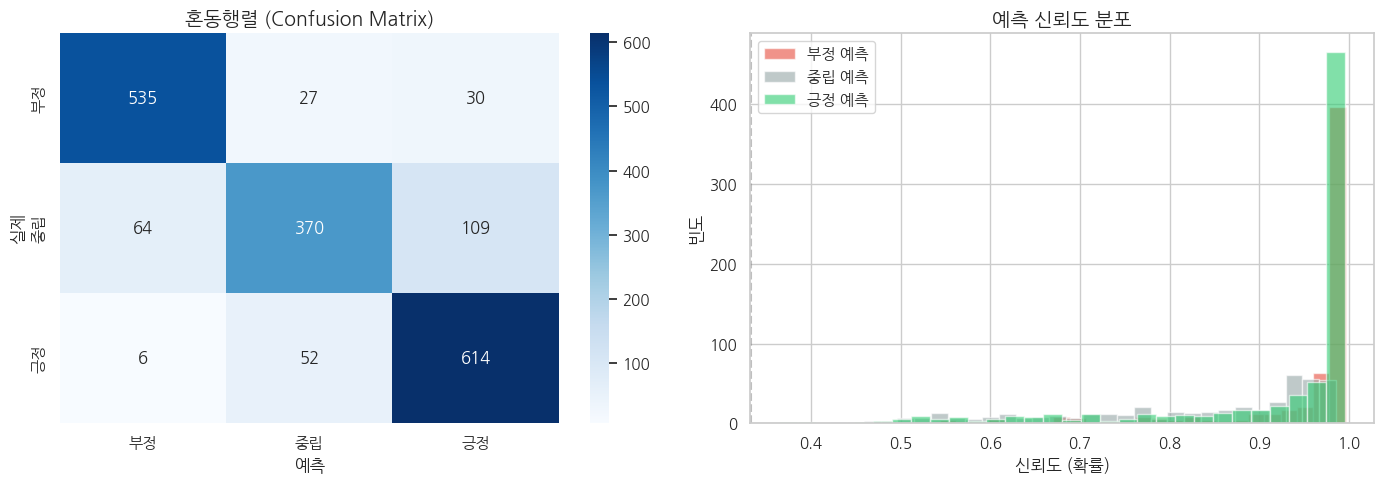

🔁 방향 반전 오답 (긍정↔부정): 36건 / 전체 1,807건 (1.99%)
   중립과의 혼동보다 이 오류가 신호의 부호를 뒤집으므로 전략에 더 치명적입니다.


In [ ]:
# === 감성분석 결과 평가 ===
from sklearn.metrics import classification_report, confusion_matrix

predictions = trainer.predict(test_dataset)
preds = np.argmax(predictions.predictions, axis=-1)
probs = torch.softmax(torch.tensor(predictions.predictions), dim=-1).numpy()

print("=== 금융 감성분석 성능 평가 ===")
print()
print(classification_report(test_labels_sub, preds, target_names=SENT_NAMES, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 혼동행렬 (3x3)
cm = confusion_matrix(test_labels_sub, preds, labels=[0, 1, 2])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=SENT_NAMES, yticklabels=SENT_NAMES)
axes[0].set_title("혼동행렬 (Confusion Matrix)", fontsize=14, fontweight='bold')
axes[0].set_xlabel("예측", fontsize=12)
axes[0].set_ylabel("실제", fontsize=12)

# 예측 클래스별 신뢰도 분포
colors_sent = {0: '#e74c3c', 1: '#95a5a6', 2: '#2ecc71'}
for c in range(3):
    mask = preds == c
    if mask.any():
        axes[1].hist(probs[mask, c], bins=30, alpha=0.6,
                     label=f'{id2name[c]} 예측', color=colors_sent[c])
axes[1].set_title("예측 신뢰도 분포", fontsize=14, fontweight='bold')
axes[1].set_xlabel("신뢰도 (확률)", fontsize=12)
axes[1].set_ylabel("빈도", fontsize=12)
axes[1].legend(fontsize=11)
axes[1].axvline(x=1/3, color='gray', linestyle='--', alpha=0.5)  # 3분류의 무작위 기준선

plt.tight_layout()
plt.show()

# 투자 관점에서 가장 위험한 오류: 긍정↔부정 '방향 반전'
flip = int(cm[0, 2] + cm[2, 0])
print(f"🔁 방향 반전 오답 (긍정↔부정): {flip}건 / 전체 {len(preds):,}건 ({flip/len(preds)*100:.2f}%)")
print("   중립과의 혼동보다 이 오류가 신호의 부호를 뒤집으므로 전략에 더 치명적입니다.")

In [ ]:
# === 오답 분석 ===
print("=== 심화: 오답 분석 ===")
print()

confidence = np.max(probs, axis=1)
y_true = np.array(test_labels_sub)
errors = preds != y_true

def show(idx, mark=""):
    print(f"  {mark}실제: {id2name[y_true[idx]]} | 예측: {id2name[preds[idx]]} "
          f"(확신도: {confidence[idx]:.3f}) | 대상: {test_aspects_sub[idx]}")
    print(f"  텍스트: {test_texts_sub[idx][:80]}...")
    print()

# 1. 확신했지만 틀린 케이스
high_conf_errors = np.where(errors & (confidence > 0.9))[0]
print(f"🔴 높은 확신으로 틀린 예측: {len(high_conf_errors)}개")
print("-" * 60)
for idx in high_conf_errors[:5]:
    show(idx)

# 2. 방향 반전 오답 (긍정↔부정)
flip_idx = np.where(((y_true == 0) & (preds == 2)) | ((y_true == 2) & (preds == 0)))[0]
print(f"\n🔁 방향 반전 오답 (긍정↔부정): {len(flip_idx)}개")
print("-" * 60)
for idx in flip_idx[:5]:
    show(idx)

# 3. 불확실한 예측 (3분류이므로 최고 확률이 0.5 미만이면 애매한 경우)
uncertain = np.where(confidence < 0.5)[0]
print(f"\n🟡 불확실한 예측 (확신도 < 0.5): {len(uncertain)}개")
print("-" * 60)
for idx in uncertain[:5]:
    show(idx, "✅ " if not errors[idx] else "❌ ")

=== 심화: 오답 분석 ===

🔴 높은 확신으로 틀린 예측: 98개
------------------------------------------------------------
  실제: 중립 | 예측: 부정 (확신도: 0.957) | 대상: 부산은행
  텍스트: 부산은행이 경남은행을 인수하더라도 자산총액은 55조원 수준으로 여전히 시중은행 대비 영세한 규모인 반면, 인수자금 상환을 위해 배당여력은 축소될...

  실제: 중립 | 예측: 긍정 (확신도: 0.990) | 대상: 로컬 브랜드
  텍스트: 올해 업종 내 사드 영향은 불가피하지만, ODM 업체들은 중국 화장품 시장의 성장과 로컬 브랜드의 성장도 공유할 수 있다는 점에서 브랜드 업체 ...

  실제: 중립 | 예측: 긍정 (확신도: 0.964) | 대상: 해외 카지노
  텍스트: 하반기 증설 허가 가능성과 38국도 개장 마카오 등 해외 카지노 증설 영향에도 불구하고 내국인 출입 카지노 수요는 지속적으로 늘어나고 있다....

  실제: 부정 | 예측: 긍정 (확신도: 0.994) | 대상: 산업자재, 화학 및 섬유부문
  텍스트: 상승중인 원재료 가격 및 동력비 증가는 수익성 추가 향상에 부담으로 작용 효성의 산업자재, 화학 및 섬유부문의 주요 원재료인 PTA 및 카프로락...

  실제: 긍정 | 예측: 중립 (확신도: 0.948) | 대상: 한전KPS
  텍스트: 현재로서 민영화에 대한 구체적인 방안이 아직 밝혀지지 않았으며 GS건설 측도 특정 업체를 거론한 바가 없기에 한전KPS의 민영화 여부를 투자 포...


🔁 방향 반전 오답 (긍정↔부정): 36개
------------------------------------------------------------
  실제: 부정 | 예측: 긍정 (확신도: 0.857) | 대상: 살로몬
  텍스트: 적자브랜드 살로몬(4Q15 영업손실 60억원 추산) 제거 효과와 라이프스타일 전년도 컨설팅 비용 소멸, 종속회사 신세계톰보이의 브랜드 리뉴얼 반.

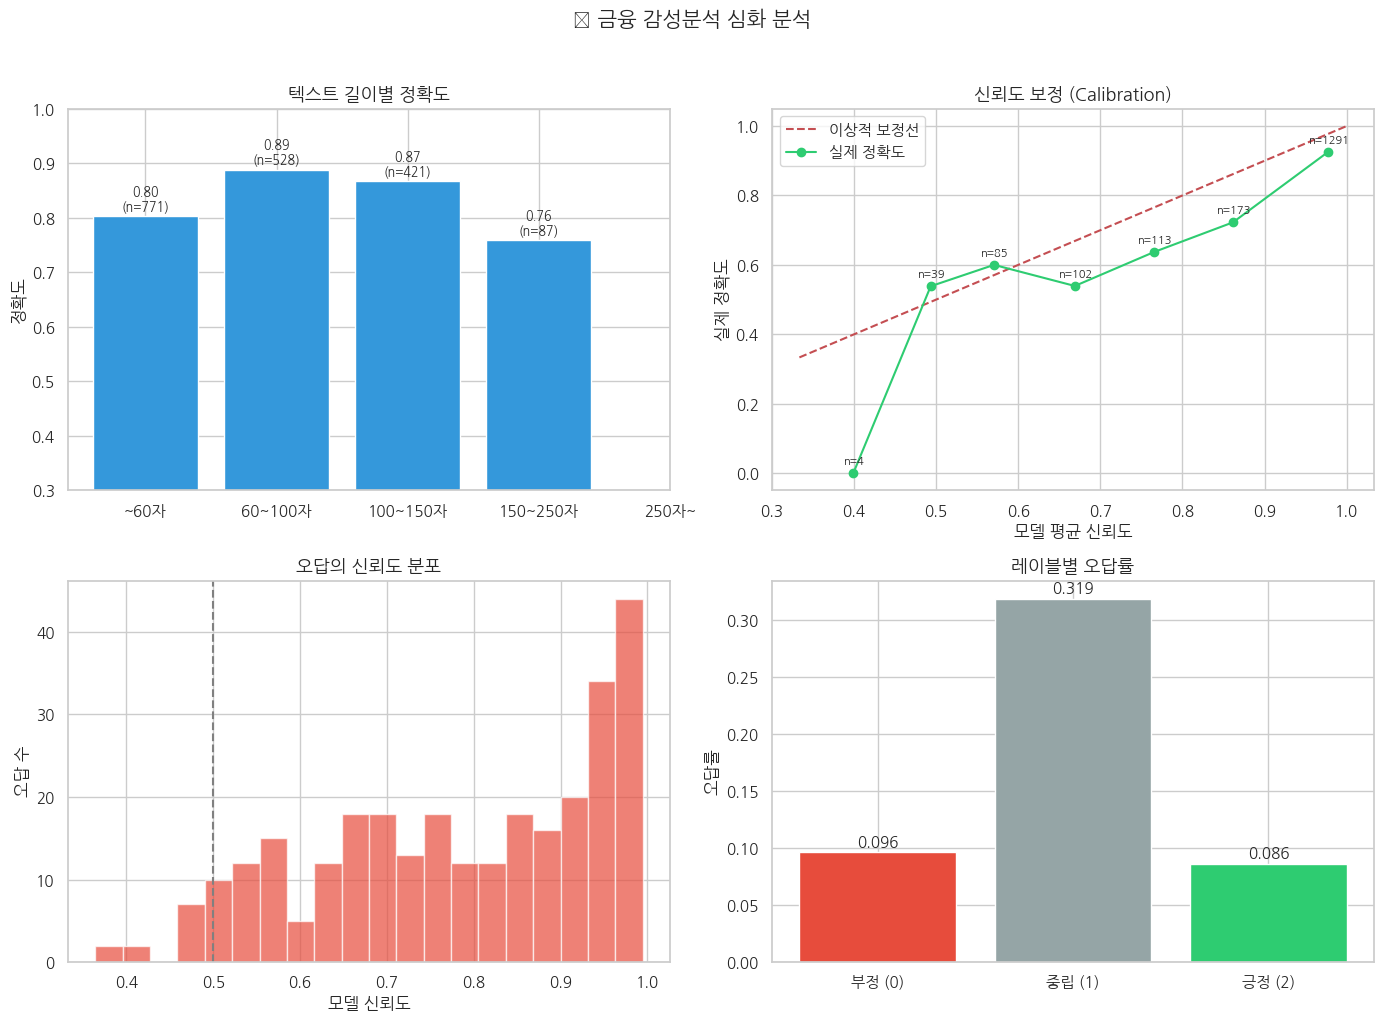


💡 분석 인사이트:
  - 가장 정확도 높은 길이대: 60~100자 (0.888)
  - 가장 정확도 낮은 길이대: 150~250자 (0.759)
  - 높은 확신 오답 비율: 34.0%


In [ ]:
# === 텍스트 길이별 성능 + 신뢰도 심화 분석 ===
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1) 텍스트 길이별 정확도 (금융 문장은 영화 리뷰보다 길어서 구간을 조정)
lengths = [len(t) for t in test_texts_sub]
length_bins = pd.cut(lengths, bins=[0, 60, 100, 150, 250, 5000],
                     labels=['~60자', '60~100자', '100~150자', '150~250자', '250자~'])

df_analysis = pd.DataFrame({
    'length_bin': length_bins,
    'correct': ~errors,
    'confidence': confidence,
    'actual': test_labels_sub,
    'predicted': preds.tolist()
})

acc_by_len = df_analysis.groupby('length_bin', observed=False)['correct'].mean()
count_by_len = df_analysis.groupby('length_bin', observed=False)['correct'].count()

axes[0, 0].bar(range(len(acc_by_len)), acc_by_len.values, color='#3498db')
axes[0, 0].set_xticks(range(len(acc_by_len)))
axes[0, 0].set_xticklabels(acc_by_len.index, rotation=0)
axes[0, 0].set_title("텍스트 길이별 정확도", fontsize=13, fontweight='bold')
axes[0, 0].set_ylabel("정확도")
axes[0, 0].set_ylim(0.3, 1.0)
for i, (v, c) in enumerate(zip(acc_by_len.values, count_by_len.values)):
    if c > 0:
        axes[0, 0].text(i, v + 0.01, f"{v:.2f}\n(n={c})", ha='center', fontsize=9)

# 2) 신뢰도 보정 (Calibration): 구간 중앙값 vs 실제 정확도
edges = np.linspace(1/3, 1.0, 8)
conf_bins = pd.cut(confidence, bins=edges, include_lowest=True)
calibration = df_analysis.groupby(conf_bins, observed=False).agg(
    acc=('correct', 'mean'), conf=('confidence', 'mean'), n=('correct', 'count'))
calibration = calibration[calibration['n'] > 0]

axes[0, 1].plot([1/3, 1], [1/3, 1], 'r--', label='이상적 보정선')
axes[0, 1].plot(calibration['conf'], calibration['acc'], 'o-', color='#2ecc71', label='실제 정확도')
for _, r in calibration.iterrows():
    axes[0, 1].annotate(f"n={int(r['n'])}", (r['conf'], r['acc']), fontsize=8,
                        textcoords='offset points', xytext=(0, 6), ha='center')
axes[0, 1].set_title("신뢰도 보정 (Calibration)", fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel("모델 평균 신뢰도")
axes[0, 1].set_ylabel("실제 정확도")
axes[0, 1].legend()

# 3) 오답의 신뢰도 분포
axes[1, 0].hist(confidence[errors], bins=20, color='#e74c3c', alpha=0.7, edgecolor='white')
axes[1, 0].set_title("오답의 신뢰도 분포", fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel("모델 신뢰도")
axes[1, 0].set_ylabel("오답 수")
axes[1, 0].axvline(x=0.5, color='gray', linestyle='--')

# 4) 레이블별 오답률
error_by_label = df_analysis.groupby('actual')['correct'].apply(lambda x: 1 - x.mean())
error_by_label = error_by_label.reindex(range(3)).fillna(0)
axes[1, 1].bar([f"{id2name[i]} ({i})" for i in range(3)], error_by_label.values,
               color=['#e74c3c', '#95a5a6', '#2ecc71'])
axes[1, 1].set_title("레이블별 오답률", fontsize=13, fontweight='bold')
axes[1, 1].set_ylabel("오답률")
for i, v in enumerate(error_by_label.values):
    axes[1, 1].text(i, v + 0.005, f"{v:.3f}", ha='center', fontsize=11)

plt.suptitle("📊 금융 감성분석 심화 분석", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

valid_acc = acc_by_len[count_by_len > 0]
print("\n💡 분석 인사이트:")
print(f"  - 가장 정확도 높은 길이대: {valid_acc.idxmax()} ({valid_acc.max():.3f})")
print(f"  - 가장 정확도 낮은 길이대: {valid_acc.idxmin()} ({valid_acc.min():.3f})")
print(f"  - 높은 확신 오답 비율: {len(high_conf_errors)/max(errors.sum(), 1)*100:.1f}%")

In [ ]:
# === 🎯 직접 금융 감성분석 체험 ===
print("=== 직접 금융 감성분석 체험 ===")
print()

# (대상 종목, 문장) — 같은 문장도 종목에 따라 결과가 달라지는지 확인하세요
test_pairs = [
    ("삼성전자", "삼성전자 3분기 영업이익이 시장 예상치를 크게 웃돌았다"),
    ("LG에너지솔루션", "LG에너지솔루션은 전기차 수요 둔화로 실적 하향 조정이 불가피하다"),
    ("현대차", "현대차의 이번 분기 실적은 전년 동기와 비슷한 수준을 기록했다"),
    ("삼성전자", "삼성전자의 HBM 공급 확대로 SK하이닉스의 점유율 하락이 우려된다"),
    ("SK하이닉스", "삼성전자의 HBM 공급 확대로 SK하이닉스의 점유율 하락이 우려된다"),
    ("카카오", "카카오는 규제 리스크가 남아 있지만 밸류에이션 매력은 높다"),  # 혼합 감성
]

model.eval()
device = next(model.parameters()).device

for aspect, sent in test_pairs:
    inputs = sent_tokenizer(sent, aspect, return_tensors='pt', truncation='only_first',
                            max_length=128, padding=True).to(device)
    with torch.no_grad():
        prob = torch.softmax(model(**inputs).logits, dim=-1)[0].cpu().numpy()

    pred = int(prob.argmax())
    print(f"입력: {sent}")
    print(f"대상: {aspect} → 판정: {id2name[pred]} (확신도: {prob[pred]:.3f})")
    for c in range(3):
        bar = "█" * int(prob[c] * 20)
        print(f"   {id2name[c]} {prob[c]:.3f} {bar}")
    print()

# 💡 전략용 점수로 쓰려면: score = P(긍정) - P(부정)  (-1 ~ +1)

=== 직접 금융 감성분석 체험 ===

입력: 삼성전자 3분기 영업이익이 시장 예상치를 크게 웃돌았다
대상: 삼성전자 → 판정: 긍정 (확신도: 0.987)
   부정 0.002 
   중립 0.011 
   긍정 0.987 ███████████████████

입력: LG에너지솔루션은 전기차 수요 둔화로 실적 하향 조정이 불가피하다
대상: LG에너지솔루션 → 판정: 부정 (확신도: 0.991)
   부정 0.991 ███████████████████
   중립 0.003 
   긍정 0.006 

입력: 현대차의 이번 분기 실적은 전년 동기와 비슷한 수준을 기록했다
대상: 현대차 → 판정: 중립 (확신도: 0.846)
   부정 0.023 
   중립 0.846 ████████████████
   긍정 0.130 ██

입력: 삼성전자의 HBM 공급 확대로 SK하이닉스의 점유율 하락이 우려된다
대상: 삼성전자 → 판정: 중립 (확신도: 0.918)
   부정 0.003 
   중립 0.918 ██████████████████
   긍정 0.078 █

입력: 삼성전자의 HBM 공급 확대로 SK하이닉스의 점유율 하락이 우려된다
대상: SK하이닉스 → 판정: 부정 (확신도: 0.993)
   부정 0.993 ███████████████████
   중립 0.004 
   긍정 0.004 

입력: 카카오는 규제 리스크가 남아 있지만 밸류에이션 매력은 높다
대상: 카카오 → 판정: 긍정 (확신도: 0.983)
   부정 0.003 
   중립 0.014 
   긍정 0.983 ███████████████████



## Part 3. 뉴스 → 다음 거래일 초과수익률

```
빅카인즈는 날짜만 제공 → 모두 장 마감 후 발행으로 간주 → 진입일 t0 = 다음 거래일 종가
초과수익률 = [종가(t0+1)/종가(t0) − 1] − [KOSPI(t0+1)/KOSPI(t0) − 1]
라벨: 학습 구간 3분위 기준 하락(0) / 보합(1) / 상승(2)
분할: 시간순 학습 70% → 검증 15% → 테스트 15%
```

평가: 정확도보다 **일별 IC(순위상관)**, **분위별 수익률**, **롱숏 누적**을 봅니다. 일별 IC는 하루 5종목 이상 필요합니다.

In [ ]:
# === Part 3 준비: 메모리 정리 + 설정 ===
# Part 2 감성 모델은 비교 기준으로 쓰므로 CPU로만 옮겨 둠
if 'model' in globals():
    model.cpu()
if 'trainer' in globals():
    del trainer
torch.cuda.empty_cache() if torch.cuda.is_available() else None

import glob, re, html
import FinanceDataReader as fdr
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("klue/bert-base")   # 수익률 모델용

UNIVERSE = {
    "005930": "삼성전자", "000660": "SK하이닉스", "373220": "LG에너지솔루션",
    "207940": "삼성바이오로직스", "005380": "현대차", "000270": "기아",
    "068270": "셀트리온", "035420": "NAVER", "035720": "카카오",
    "005490": "POSCO홀딩스", "051910": "LG화학", "006400": "삼성SDI",
    "105560": "KB금융", "055550": "신한지주", "012330": "현대모비스",
    "028260": "삼성물산", "066570": "LG전자", "003550": "LG",
    "034730": "SK", "096770": "SK이노베이션", "017670": "SK텔레콤",
    "030200": "KT", "015760": "한국전력", "032830": "삼성생명",
    "086790": "하나금융지주", "009150": "삼성전기", "010130": "고려아연",
    "012450": "한화에어로스페이스", "329180": "HD현대중공업", "259960": "크래프톤",
}
RET_NAMES = {0: "하락", 1: "보합", 2: "상승"}

BIGKINDS_GLOB = "NewsResult_*.xlsx"   # 왼쪽 📁 패널에 업로드한 빅카인즈 엑셀

# 제목에서 종목을 찾을 때 쓰는 별칭 (여기 없는 종목은 종목명 그대로 사용)
ALIASES = {
    "005930": ["삼성전자", "삼전"],                  # '삼전닉스'도 함께 잡힘
    "000660": ["SK하이닉스", "하이닉스", "삼전닉스"],
    "373220": ["LG에너지솔루션", "LG엔솔"],
    "207940": ["삼성바이오로직스", "삼성바이오"],
    "005380": ["현대차", "현대자동차"],
    "005490": ["POSCO홀딩스", "포스코홀딩스"],
    "035420": ["NAVER", "네이버"],
    "055550": ["신한지주", "신한금융"],
    "086790": ["하나금융"],
    "015760": ["한국전력", "한전"],
    "012450": ["한화에어로스페이스", "한화에어로"],
}
# 이름이 짧아 다른 회사와 겹치는 종목은 제목 매칭에서 제외 ('LG'는 'LG전자' 제목에도 걸림)
AMBIGUOUS = {"003550", "034730", "030200"}   # LG, SK, KT

print(f"매칭 대상: {len(UNIVERSE) - len(AMBIGUOUS)}개 종목 (제외: LG, SK, KT)")

매칭 대상: 27개 종목 (제외: LG, SK, KT)


In [ ]:
# === 빅카인즈 엑셀 불러오기 + 제목 기준 종목 매칭 ===
files = sorted(glob.glob(BIGKINDS_GLOB))
assert files, f"'{BIGKINDS_GLOB}' 파일이 없습니다. Colab 왼쪽 📁 패널에 빅카인즈 엑셀을 업로드하세요."

frames = []
for f in files:
    d = pd.read_excel(f)
    print(f"📄 {os.path.basename(f)}: {len(d):,}건")
    frames.append(d)
bk = pd.concat(frames, ignore_index=True)

# 빅카인즈가 '중복'·'예외'로 표시한 기사 제외 + 파일 간 중복 제거 (URL 기준)
if '분석제외 여부' in bk.columns:
    bk = bk[bk['분석제외 여부'].isna()]
bk = bk.dropna(subset=['일자', '제목'])
bk = bk.drop_duplicates(subset=['URL'] if 'URL' in bk.columns else ['일자', '제목'])

# 빅카인즈는 날짜만 제공 → 23:59 발행으로 간주 (= 다음 거래일 종가 진입, 룩어헤드 방지)
bk['datetime'] = (pd.to_datetime(bk['일자'].astype(str).str[:8], format='%Y%m%d')
                  + pd.Timedelta(hours=23, minutes=59))
bk['title'] = bk['제목'].astype(str).map(html.unescape).str.strip()

# 제목에 종목명(별칭)이 나오는 기사만 해당 종목에 배정 (한 기사가 여러 종목에 배정될 수 있음)
patterns = {code: re.compile("|".join(map(re.escape, ALIASES.get(code, [name]))))
            for code, name in UNIVERSE.items() if code not in AMBIGUOUS}
rows = []
for r in bk.itertuples(index=False):
    for code, pat in patterns.items():
        if pat.search(r.title):
            rows.append({'datetime': r.datetime, 'code': code, 'name': UNIVERSE[code],
                         'title': r.title, 'source': getattr(r, '언론사', ''),
                         'id': getattr(r, 'URL', '')})
news_raw = pd.DataFrame(rows)
assert len(news_raw) > 0, "제목에 종목명이 들어간 기사가 없습니다. ALIASES를 확인하세요."

matched = news_raw['id'].nunique()
print(f"\n전체 기사 {len(bk):,}건 중 제목에 종목명이 있는 기사: {matched:,}건 ({matched/len(bk)*100:.1f}%)")
print(f"종목 배정 후: {len(news_raw):,}건 ({news_raw['code'].nunique()}개 종목)\n")

span = (news_raw.groupby('name')['datetime'].agg(['min', 'max', 'count'])
        .sort_values('count', ascending=False))
span['min'] = span['min'].dt.date
span['max'] = span['max'].dt.date
print(span.to_string())

if news_raw['code'].nunique() < 5:
    print("\n⚠️ 종목이 5개 미만이면 일별 IC(종목 간 비교)를 계산할 수 없습니다.")
    print("   파이프라인 점검용으로는 진행해도 되지만, 의미 있는 평가를 위해 종목을 더 내려받으세요.")

📄 NewsResult_20251023-20261023.xlsx: 7,947건

전체 기사 7,671건 중 제목에 종목명이 있는 기사: 2,386건 (31.1%)
종목 배정 후: 3,159건 (22개 종목)

                  min         max  count
name                                    
삼성전자       2025-10-23  2026-10-23   1988
SK하이닉스     2025-10-24  2026-10-23    922
현대차        2025-10-30  2026-10-02     76
삼성전기       2026-02-26  2026-10-22     30
NAVER      2025-10-28  2026-09-18     24
LG전자       2025-12-26  2026-10-07     21
카카오        2025-12-18  2026-09-11     17
삼성물산       2025-10-29  2026-10-20     15
삼성생명       2025-10-30  2026-06-22     15
삼성바이오로직스   2025-11-10  2026-10-06      9
한국전력       2026-01-22  2026-10-12      8
기아         2025-11-03  2026-04-10      8
삼성SDI      2026-03-13  2026-10-22      4
SK텔레콤      2026-04-09  2026-09-15      4
크래프톤       2025-11-02  2026-08-29      4
현대모비스      2025-12-16  2026-07-17      3
KB금융       2026-06-07  2026-09-09      3
LG에너지솔루션   2025-11-18  2026-03-24      3
셀트리온       2025-12-17  2026-02-08      2
LG화학       2025-11-18 

In [ ]:
# === 주가 데이터 + 다음 거래일 초과수익률 계산 ===
price_start = (news_raw['datetime'].min() - pd.Timedelta(days=10)).strftime('%Y-%m-%d')

kospi = fdr.DataReader('KS11', price_start)['Close']
kospi.index = pd.DatetimeIndex(kospi.index).normalize()
trade_days = kospi.index
mkt_fwd = kospi.pct_change(fill_method=None).shift(-1)   # t → t+1 시장 수익률

names_used = news_raw[['code', 'name']].drop_duplicates('code')
fwd_ret = {}
for code, name in zip(names_used['code'], names_used['name']):
    try:
        px = fdr.DataReader(code, price_start)['Close']
    except Exception as e:
        print(f"⚠️ {name} 주가 조회 실패: {e}")
        continue
    px.index = pd.DatetimeIndex(px.index).normalize()
    px = px.reindex(trade_days)                       # 거래정지일 등은 NaN
    fwd_ret[code] = px.pct_change(fill_method=None).shift(-1) - mkt_fwd   # 초과수익률

CUTOFF = pd.Timedelta(hours=15, minutes=20)

def entry_day(ts):
    """발행 시각 기준으로 실제 매매 가능한 첫 거래일 (그날 종가에 진입)"""
    d = ts.normalize()
    pos = trade_days.searchsorted(d)
    if pos < len(trade_days) and trade_days[pos] == d and (ts - d) <= CUTOFF:
        return trade_days[pos]
    pos = trade_days.searchsorted(d, side='right')
    return trade_days[pos] if pos < len(trade_days) else pd.NaT

news_df = news_raw.copy()
news_df['t0'] = news_df['datetime'].apply(entry_day)
news_df['ret'] = [fwd_ret[c].get(t, np.nan) if (c in fwd_ret and pd.notna(t)) else np.nan
                  for c, t in zip(news_df['code'], news_df['t0'])]
news_df = news_df.dropna(subset=['t0', 'ret']).copy()
news_df['text'] = news_df['title'].apply(clean_fin_text)
news_df = news_df[news_df['text'].str.len() > 0].sort_values('t0').reset_index(drop=True)

print(f"라벨 계산 완료: {len(news_df):,}건 / 거래일 {news_df['t0'].nunique()}일 "
      f"({news_df['t0'].min():%Y-%m-%d} ~ {news_df['t0'].max():%Y-%m-%d})")
print(f"초과수익률 분포(%): " +
      ", ".join(f"{k} {v*100:+.2f}" for k, v in
                news_df['ret'].quantile([0.05, 0.25, 0.5, 0.75, 0.95]).items()))

print("\n--- 진입일 예시 (발행일 → 다음 거래일 진입) ---")
for _, r in news_df.sample(min(5, len(news_df)), random_state=0).sort_values('datetime').iterrows():
    print(f"  발행 {r['datetime']:%Y-%m-%d} → 진입 {r['t0']:%Y-%m-%d} | 초과수익 {r['ret']*100:+.2f}% "
          f"| {r['name']} | {r['title'][:35]}")

라벨 계산 완료: 3,145건 / 거래일 241일 (2025-10-24 ~ 2026-10-22)
초과수익률 분포(%): 0.05 -3.81, 0.25 -1.44, 0.5 -0.09, 0.75 +1.54, 0.95 +5.06

--- 진입일 예시 (발행일 → 다음 거래일 진입) ---
  발행 2025-12-31 → 진입 2026-01-02 | 초과수익 +4.04% | 삼성전자 | “삼성전자 계속 웃겠네” 범용 D램 첫 9달러 돌파
  발행 2026-01-16 → 진입 2026-01-19 | 초과수익 -2.36% | SK하이닉스 | SK하이닉스 역대급 성과급  내달 1인당 1.4억 지급한다
  발행 2026-03-02 → 진입 2026-03-03 | 초과수익 +2.47% | SK하이닉스 | 현대차증권, 삼성전자 SK하이닉스가 35%로 높은 비중 차지
  발행 2026-05-06 → 진입 2026-05-07 | 초과수익 -1.21% | 삼성전자 | “영업이익 15% 성과급으로” 삼성전자 노조 요구, ‘주주 잔여
  발행 2026-10-12 → 진입 2026-10-13 | 초과수익 +0.65% | 삼성전자 | “삼성전자 60만원 가나요” KB證 “영업익 세계 1위 눈길” 


In [ ]:
# === 시간순 분할 + 3분위 라벨링 (임계값은 학습 구간만으로) ===
days = np.sort(news_df['t0'].unique())
n_days = len(days)
tr_end, va_end = days[int(n_days * 0.70)], days[int(n_days * 0.85)]

# 경계일은 비워서(엠바고) 구간 간 정보가 섞이지 않게 함
train_df_r = news_df[news_df['t0'] < tr_end].copy()
val_df_r = news_df[(news_df['t0'] > tr_end) & (news_df['t0'] < va_end)].copy()
test_df_r = news_df[news_df['t0'] > va_end].copy()

q_lo, q_hi = train_df_r['ret'].quantile([1/3, 2/3]).values

def to_label(r):
    return np.select([r <= q_lo, r >= q_hi], [0, 2], default=1)

for d in (train_df_r, val_df_r, test_df_r):
    d['label'] = to_label(d['ret'].values)

print(f"3분위 임계값 (학습 구간 기준): 하락 ≤ {q_lo*100:+.2f}%  |  상승 ≥ {q_hi*100:+.2f}%\n")
for nm, d in [('학습', train_df_r), ('검증', val_df_r), ('테스트', test_df_r)]:
    dist = d['label'].value_counts(normalize=True).reindex(range(3)).fillna(0)
    print(f"  {nm}: {len(d):6,}건 | {d['t0'].min():%Y-%m-%d} ~ {d['t0'].max():%Y-%m-%d} "
          f"({d['t0'].nunique()}일) | " +
          ", ".join(f"{RET_NAMES[i]} {p*100:.1f}%" for i, p in dist.items()))

print("\n💡 검증·테스트의 라벨 비율이 1/3씩이 아닌 건 정상입니다 (시장 국면이 학습 구간과 다르기 때문).")

3분위 임계값 (학습 구간 기준): 하락 ≤ -0.90%  |  상승 ≥ +0.95%

  학습:  2,091건 | 2025-10-24 ~ 2026-07-03 (168일) | 하락 33.4%, 보합 33.1%, 상승 33.5%
  검증:    563건 | 2026-07-07 ~ 2026-08-26 (35일) | 하락 33.9%, 보합 36.6%, 상승 29.5%
  테스트:    462건 | 2026-08-28 ~ 2026-10-22 (36일) | 하락 32.0%, 보합 41.1%, 상승 26.8%

💡 검증·테스트의 라벨 비율이 1/3씩이 아닌 건 정상입니다 (시장 국면이 학습 구간과 다르기 때문).


In [ ]:
# === 수익률 분류 모델 학습 (검증셋으로 에폭 선택) ===
from transformers import AutoModelForSequenceClassification, Trainer, TrainingArguments, set_seed

def make_ds(df):
    return TextClassificationDataset(df['text'].tolist(), df['label'].tolist(), tokenizer,
                                     max_len=64, text_pairs=df['name'].tolist())

ret_train_ds, ret_val_ds, ret_test_ds = make_ds(train_df_r), make_ds(val_df_r), make_ds(test_df_r)

set_seed(42)
model_mc = AutoModelForSequenceClassification.from_pretrained(
    "klue/bert-base", num_labels=3,
    id2label={i: n for i, n in RET_NAMES.items()},
    label2id={n: i for i, n in RET_NAMES.items()},
)

training_args_mc = TrainingArguments(
    output_dir="./return_model",
    num_train_epochs=3,
    learning_rate=2e-5,              # 라벨 노이즈가 크므로 Part 2보다 보수적으로
    per_device_train_batch_size=32,
    per_device_eval_batch_size=128,
    warmup_steps=100,
    weight_decay=0.01,
    logging_steps=50,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    report_to="none",
    fp16=torch.cuda.is_available(),
)

trainer_mc = Trainer(
    model=model_mc,
    args=training_args_mc,
    train_dataset=ret_train_ds,
    eval_dataset=ret_val_ds,          # ← Part 2와 달리 테스트셋은 마지막 평가에만 사용
    compute_metrics=compute_metrics,  # Part 2에서 정의 (Macro-F1)
)

print(f"학습 {len(ret_train_ds):,}건 / 검증 {len(ret_val_ds):,}건 / 테스트 {len(ret_test_ds):,}건")
trainer_mc.train()
print("\n✅ 학습 완료!")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: klue/bert-base
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


학습 2,091건 / 검증 563건 / 테스트 462건


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,1.122127,1.131866,0.351687,0.309001
2,1.087600,1.156099,0.342806,0.298539
3,1.064984,1.160063,0.344583,0.325895


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


✅ 학습 완료!


=== 다음 날 초과수익률 3분류 — 테스트 구간 ===

              precision    recall  f1-score   support

          하락     0.3534    0.3176    0.3345       148
          보합     0.4651    0.6316    0.5357       190
          상승     0.2958    0.1694    0.2154       124

    accuracy                         0.4069       462
   macro avg     0.3714    0.3728    0.3619       462
weighted avg     0.3839    0.4069    0.3853       462

기준선: 무작위 33.3% / 최빈 클래스만 찍기 41.1%  →  모델 정확도 40.7%


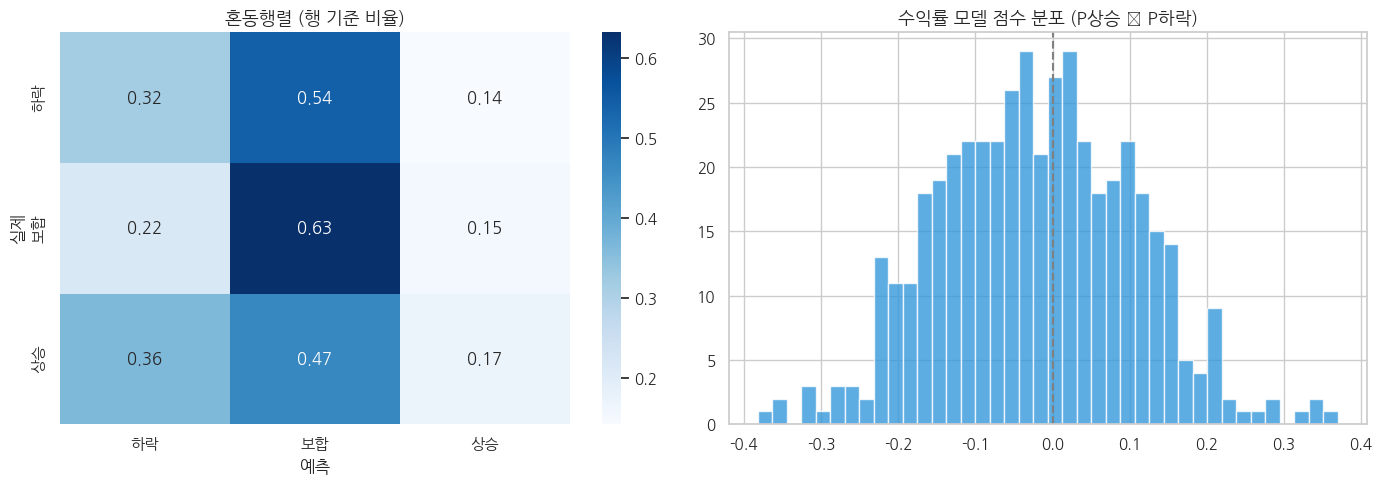

💡 점수가 0 근처에 좁게 몰려 있다면, 모델이 뉴스 제목에서 확신할 근거를 별로 찾지 못했다는 뜻입니다.


In [ ]:
# === 분류 성능 평가 (테스트 구간) ===
from sklearn.metrics import classification_report, confusion_matrix

out_r = trainer_mc.predict(ret_test_ds)
probs_r = torch.softmax(torch.tensor(out_r.predictions), dim=-1).numpy()
pred_r = probs_r.argmax(axis=1)
y_r = test_df_r['label'].values

print("=== 다음 날 초과수익률 3분류 — 테스트 구간 ===\n")
print(classification_report(y_r, pred_r, labels=[0, 1, 2],
                            target_names=list(RET_NAMES.values()), digits=4, zero_division=0))
majority = np.bincount(y_r, minlength=3).max() / len(y_r)
print(f"기준선: 무작위 33.3% / 최빈 클래스만 찍기 {majority*100:.1f}%  →  모델 정확도 {(pred_r == y_r).mean()*100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cm_r = confusion_matrix(y_r, pred_r, labels=[0, 1, 2])
cm_rn = cm_r / cm_r.sum(axis=1, keepdims=True).clip(min=1)
sns.heatmap(cm_rn, annot=True, fmt='.2f', cmap='Blues', ax=axes[0],
            xticklabels=list(RET_NAMES.values()), yticklabels=list(RET_NAMES.values()))
axes[0].set_title("혼동행렬 (행 기준 비율)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("예측"); axes[0].set_ylabel("실제")

test_df_r['score_ret'] = probs_r[:, 2] - probs_r[:, 0]    # 상승확률 − 하락확률
axes[1].hist(test_df_r['score_ret'], bins=40, color='#3498db', alpha=0.8)
axes[1].set_title("수익률 모델 점수 분포 (P상승 − P하락)", fontsize=13, fontweight='bold')
axes[1].axvline(0, color='gray', linestyle='--')
plt.tight_layout()
plt.show()
print("💡 점수가 0 근처에 좁게 몰려 있다면, 모델이 뉴스 제목에서 확신할 근거를 별로 찾지 못했다는 뜻입니다.")

평가 단위: (날짜, 종목) 89개 / 거래일 36일 / 하루 평균 2.5종목

점수             |    IC 평균 |   IC>0 비율 |     t값 |   일수
-------------------------------------------------------
수익률 모델         |  +0.3000 |    100.0% |   +nan |    1
감성 모델(Part 2)  |  -0.2000 |      0.0% |   +nan |    1


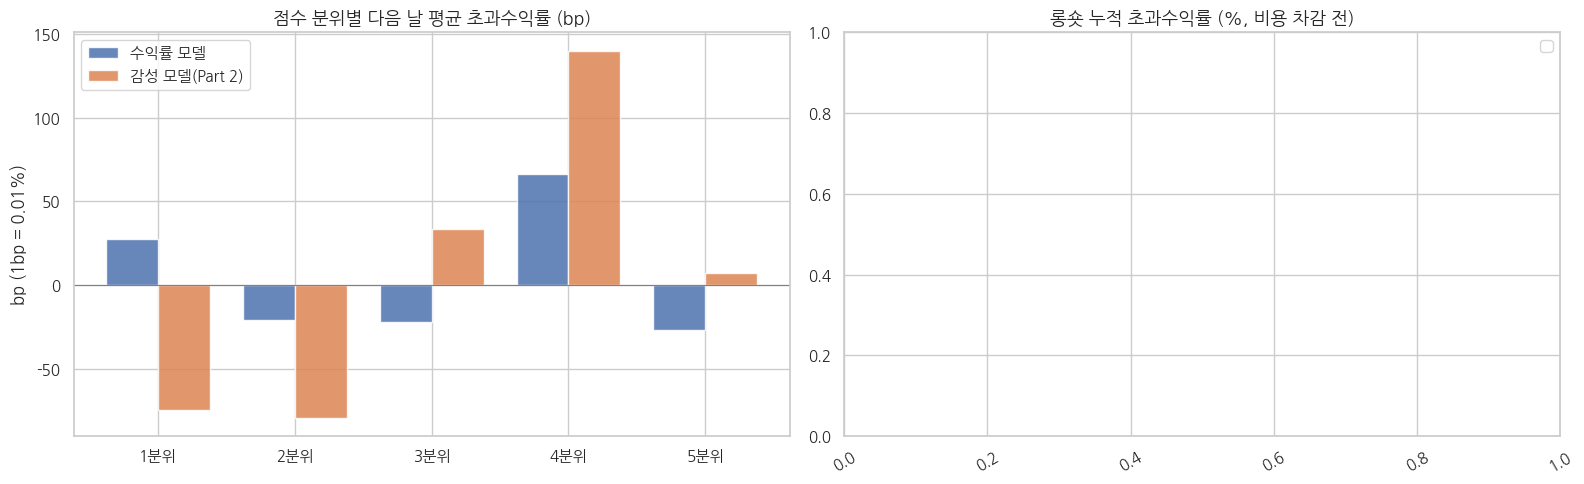


📌 해석 가이드
  - IC t값의 절댓값이 2 미만이면 노이즈와 구분하기 어렵습니다.
  - 테스트 기간 거래일이 적으면 결론이 이릅니다 → 빅카인즈에서 종목·기간을 늘려 다시 받으세요.
  - 롱숏은 매일 리밸런싱 가정이라, 왕복 거래비용(세금 포함)을 빼면 크게 줄어듭니다.


In [ ]:
# === 전략 관점 평가: 감성 모델 vs 수익률 모델 ===
from scipy.stats import spearmanr

dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def score_sentiment(df, batch=128):
    """Part 2 감성 모델로 P(긍정) − P(부정) 점수 계산"""
    m = model.to(dev).eval()
    scores = []
    for i in range(0, len(df), batch):
        chunk = df.iloc[i:i + batch]
        enc = sent_tokenizer(chunk['text'].tolist(), chunk['name'].tolist(),
                             truncation='only_first', max_length=128,
                             padding=True, return_tensors='pt').to(dev)
        with torch.no_grad():
            p = torch.softmax(m(**enc).logits, dim=-1).cpu().numpy()
        scores.append(p[:, 2] - p[:, 0])
    m.cpu()
    return np.concatenate(scores)

has_sent = 'model' in globals() and 'sent_tokenizer' in globals()
if has_sent:
    test_df_r['score_sent'] = score_sentiment(test_df_r)
else:
    print("⚠️ Part 2 감성 모델이 없어 수익률 모델만 평가합니다.")

score_cols = {'score_ret': '수익률 모델'}
if has_sent:
    score_cols['score_sent'] = '감성 모델(Part 2)'

# (날짜, 종목) 단위로 집계
agg = (test_df_r.groupby(['t0', 'code'])
       .agg(**{c: (c, 'mean') for c in score_cols}, ret=('ret', 'first'), n_news=('title', 'count'))
       .reset_index())
print(f"평가 단위: (날짜, 종목) {len(agg):,}개 / 거래일 {agg['t0'].nunique()}일 / "
      f"하루 평균 {agg.groupby('t0').size().mean():.1f}종목\n")

def daily_ic(df, col, min_names=5):
    ics = []
    for _, g in df.groupby('t0'):
        if len(g) >= min_names and g[col].nunique() > 1:
            ics.append(spearmanr(g[col], g['ret'])[0])
    ics = pd.Series(ics, dtype=float).dropna()
    t = ics.mean() / ics.std() * np.sqrt(len(ics)) if len(ics) > 1 else np.nan
    return ics, t

print(f"{'점수':14s} | {'IC 평균':>8s} | {'IC>0 비율':>9s} | {'t값':>6s} | {'일수':>4s}")
print("-" * 55)
for col, nm in score_cols.items():
    ics, t = daily_ic(agg, col)
    if len(ics):
        print(f"{nm:14s} | {ics.mean():+8.4f} | {(ics > 0).mean()*100:8.1f}% | {t:+6.2f} | {len(ics):4d}")
    else:
        print(f"{nm:14s} | 하루 5종목 이상인 날이 없어 IC 계산 불가")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1) 분위별 평균 초과수익률
width = 0.38
for k, (col, nm) in enumerate(score_cols.items()):
    q = pd.qcut(agg[col].rank(method='first'), 5, labels=[1, 2, 3, 4, 5])
    qret = agg.groupby(q, observed=False)['ret'].mean() * 1e4   # bp 단위
    axes[0].bar(np.arange(5) + (k - 0.5) * width * (len(score_cols) > 1), qret.values,
                width=width, label=nm, alpha=0.85)
axes[0].set_xticks(range(5))
axes[0].set_xticklabels([f"{i}분위" for i in range(1, 6)])
axes[0].axhline(0, color='gray', linewidth=0.8)
axes[0].set_title("점수 분위별 다음 날 평균 초과수익률 (bp)", fontsize=13, fontweight='bold')
axes[0].set_ylabel("bp (1bp = 0.01%)")
axes[0].legend()

# 2) 일별 롱숏 누적 (상위 1/3 − 하위 1/3, 비용 차감 전)
for col, nm in score_cols.items():
    ls = []
    for t, g in agg.groupby('t0'):
        if len(g) >= 6:
            r = g[col].rank(pct=True)
            ls.append((t, g.loc[r > 2/3, 'ret'].mean() - g.loc[r <= 1/3, 'ret'].mean()))
    if ls:
        ls = pd.Series(dict(ls))
        axes[1].plot(ls.index, ls.cumsum() * 100, label=f"{nm} (일평균 {ls.mean()*1e4:+.1f}bp)")
axes[1].axhline(0, color='gray', linewidth=0.8)
axes[1].set_title("롱숏 누적 초과수익률 (%, 비용 차감 전)", fontsize=13, fontweight='bold')
axes[1].legend()
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

print("\n📌 해석 가이드")
print("  - IC t값의 절댓값이 2 미만이면 노이즈와 구분하기 어렵습니다.")
print("  - 테스트 기간 거래일이 적으면 결론이 이릅니다 → 빅카인즈에서 종목·기간을 늘려 다시 받으세요.")
print("  - 롱숏은 매일 리밸런싱 가정이라, 왕복 거래비용(세금 포함)을 빼면 크게 줄어듭니다.")

In [ ]:
# === Part 4-1: 시가·종가 수익률 (h0, h1) ===
PAIR = {"005930": "삼성전자", "000660": "SK하이닉스"}
p_start = (news_df['t0'].min() - pd.Timedelta(days=60)).strftime('%Y-%m-%d')

def load_ohlc(sym):
    d = fdr.DataReader(sym, p_start)[['Open', 'Close']].astype(float)
    d.index = pd.DatetimeIndex(d.index).normalize()
    d.loc[d['Open'] <= 0, 'Open'] = np.nan        # 거래정지일 등 시가 0 방어
    return d

px = {'KOSPI': load_ohlc('KS11')}
for code, name in PAIR.items():
    px[name] = load_ohlc(code)
cal = px['KOSPI'].index

rets = pd.DataFrame(index=cal)
for k, d in px.items():
    d = d.reindex(cal)
    rets[f'{k}_h0'] = d['Close'] / d['Open'] - 1                 # t0 시가 → t0 종가
    rets[f'{k}_h1'] = d['Close'].shift(-1) / d['Close'] - 1      # t0 종가 → t0+1 종가

print("일평균 수익률·변동성 (%)")
print(rets.agg(['mean', 'std']).mul(100).round(3).T.to_string())

일평균 수익률·변동성 (%)
            mean    std
KOSPI_h0  -0.026  2.370
KOSPI_h1   0.241  3.299
삼성전자_h0    0.047  3.068
삼성전자_h1    0.493  4.648
SK하이닉스_h0  0.203  3.655
SK하이닉스_h1  0.716  5.618


감성 점수 계산: 2,899건 → 뉴스가 있는 거래일 241일 (하루 평균 12.0건)
두 종목 모두 뉴스가 있는 날: 218일
평균 감성 S: +0.223  (0보다 크면 긍정 편향)


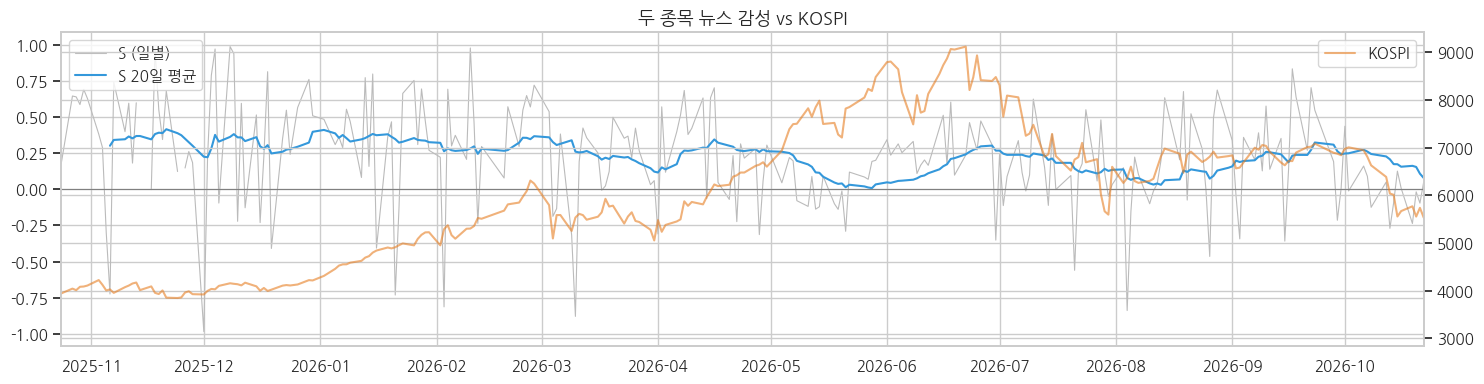

In [ ]:
# === Part 4-2: 감성 점수 계산 + 일별 집계 ===
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def score_sentiment(df, batch=128):
    """Part 2 감성 모델로 P(긍정) − P(부정) 점수 계산"""
    m = model.to(dev).eval()
    out = []
    for i in range(0, len(df), batch):
        chunk = df.iloc[i:i + batch]
        enc = sent_tokenizer(chunk['text'].tolist(), chunk['name'].tolist(),
                             truncation='only_first', max_length=128,
                             padding=True, return_tensors='pt').to(dev)
        with torch.no_grad():
            p = torch.softmax(m(**enc).logits, dim=-1).cpu().numpy()
        out.append(p[:, 2] - p[:, 0])
    m.cpu()
    return np.concatenate(out)

pair_news = news_df[news_df['code'].isin(PAIR)].copy()
pair_news['score'] = score_sentiment(pair_news)

def add_delta(s, win=20):
    """과거 win거래일 평균 대비 변화량 (당일 값은 평균에 넣지 않음)"""
    return s - s.rolling(win, min_periods=win // 2).mean().shift(1)

# 시장 감성: 두 종목 기사 전체의 하루 평균
mkt = pair_news.groupby('t0')['score'].agg(['mean', 'count'])
sig = pd.DataFrame(index=cal)
sig['S'] = mkt['mean'].reindex(cal)
sig['n'] = mkt['count'].reindex(cal).fillna(0).astype(int)
sig['dS'] = add_delta(sig['S'])

# 종목별 감성 (페어용)
per = pair_news.groupby(['t0', 'name'])['score'].mean().unstack('name').reindex(cal)
sig['S_삼성'] = per.get('삼성전자')
sig['S_하닉'] = per.get('SK하이닉스')
sig['D'] = sig['S_삼성'] - sig['S_하닉']
sig['dD'] = add_delta(sig['D'])

valid = sig['S'].notna()
print(f"감성 점수 계산: {len(pair_news):,}건 → 뉴스가 있는 거래일 {valid.sum()}일 "
      f"(하루 평균 {sig.loc[valid, 'n'].mean():.1f}건)")
print(f"두 종목 모두 뉴스가 있는 날: {sig['D'].notna().sum()}일")
print(f"평균 감성 S: {sig['S'].mean():+.3f}  (0보다 크면 긍정 편향)")

fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(sig.index, sig['S'], color='#bbbbbb', linewidth=0.8, label='S (일별)')
ax.plot(sig.index, sig['S'].rolling(20, min_periods=10).mean(), color='#3498db', label='S 20일 평균')
ax.axhline(0, color='gray', linewidth=0.8)
ax2 = ax.twinx()
ax2.plot(px['KOSPI'].index, px['KOSPI']['Close'], color='#e67e22', alpha=0.6, label='KOSPI')
ax.set_title("두 종목 뉴스 감성 vs KOSPI", fontsize=13, fontweight='bold')
ax.legend(loc='upper left'); ax2.legend(loc='upper right')
ax.set_xlim(sig.index[valid].min(), sig.index[valid].max())
plt.tight_layout(); plt.show()

=== 감성 신호 vs 다음 거래일 수익률 (전체 기간) ===
신호        대상  Pearson  Spearman     t값  일수
 S  KOSPI_h0   -0.053     0.009 -0.814 241
 S  KOSPI_h1   -0.065    -0.037 -1.005 241
 S   삼성전자_h0   -0.067    -0.028 -1.037 241
 S   삼성전자_h1   -0.047    -0.024 -0.725 241
 S SK하이닉스_h0   -0.015     0.013 -0.238 241
 S SK하이닉스_h1   -0.046    -0.032 -0.708 241
dS  KOSPI_h0   -0.080    -0.045 -1.220 231
dS  KOSPI_h1   -0.075    -0.028 -1.132 231
dS   삼성전자_h0   -0.110    -0.073 -1.671 231
dS   삼성전자_h1   -0.057    -0.024 -0.859 231
dS SK하이닉스_h0   -0.055    -0.030 -0.838 231
dS SK하이닉스_h1   -0.056    -0.025 -0.845 231

=== 반기별 안정성 (ΔS 기준, 분할일 2026-04-23) ===
  KOSPI_h0: 전반기 r=-0.046 (t=-0.48, 111일) | 후반기 r=-0.125 (t=-1.37, 121일)
  KOSPI_h1: 전반기 r=-0.124 (t=-1.31, 111일) | 후반기 r=-0.043 (t=-0.47, 121일)


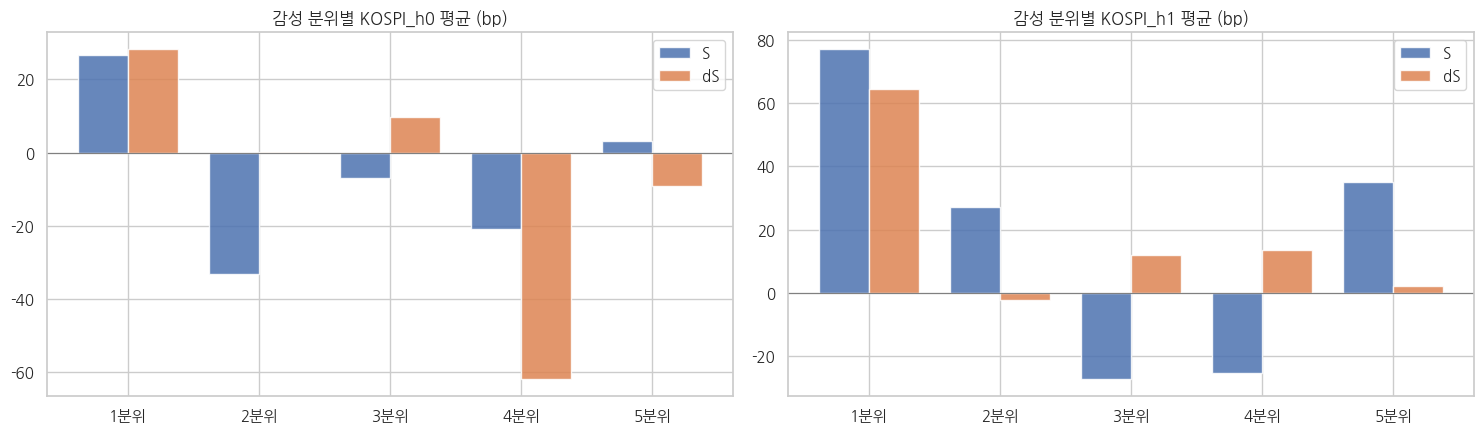


📌 t값 절댓값 2 이상 + 반기별 부호 유지 + 분위 단조 증가, 세 가지가 함께 맞아야 의미 있는 신호입니다.


In [ ]:
# === Part 4-3: 시장 타이밍 — 감성과 다음 거래일 수익률의 관계 ===
from scipy.stats import spearmanr, pearsonr

def corr_row(x, y):
    d = pd.concat([x, y], axis=1).dropna()
    if len(d) < 10:
        return np.nan, np.nan, np.nan, len(d)
    r = pearsonr(d.iloc[:, 0], d.iloc[:, 1])[0]
    rho = spearmanr(d.iloc[:, 0], d.iloc[:, 1])[0]
    t = r * np.sqrt((len(d) - 2) / max(1 - r ** 2, 1e-12))
    return r, rho, t, len(d)

targets = ['KOSPI_h0', 'KOSPI_h1', '삼성전자_h0', '삼성전자_h1', 'SK하이닉스_h0', 'SK하이닉스_h1']
rows = []
for s in ['S', 'dS']:
    for tg in targets:
        r, rho, t, n = corr_row(sig[s], rets[tg])
        rows.append({'신호': s, '대상': tg, 'Pearson': r, 'Spearman': rho, 't값': t, '일수': n})
res = pd.DataFrame(rows)
print("=== 감성 신호 vs 다음 거래일 수익률 (전체 기간) ===")
print(res.round(3).to_string(index=False))

# 반기별 안정성: 같은 부호가 유지되는가
mid = sig.index[valid][len(sig.index[valid]) // 2]
print(f"\n=== 반기별 안정성 (ΔS 기준, 분할일 {mid:%Y-%m-%d}) ===")
for tg in ['KOSPI_h0', 'KOSPI_h1']:
    r1 = corr_row(sig.loc[:mid, 'dS'], rets.loc[:mid, tg])
    r2 = corr_row(sig.loc[mid:, 'dS'], rets.loc[mid:, tg])
    print(f"  {tg}: 전반기 r={r1[0]:+.3f} (t={r1[2]:+.2f}, {r1[3]}일) | 후반기 r={r2[0]:+.3f} (t={r2[2]:+.2f}, {r2[3]}일)")

# 분위별 평균 수익률
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, tg in zip(axes, ['KOSPI_h0', 'KOSPI_h1']):
    for k, s in enumerate(['S', 'dS']):
        d = pd.concat([sig[s], rets[tg]], axis=1).dropna()
        q = pd.qcut(d[s].rank(method='first'), 5, labels=[1, 2, 3, 4, 5])
        m = d.groupby(q, observed=False)[tg].mean() * 1e4
        ax.bar(np.arange(5) + (k - 0.5) * 0.38, m.values, width=0.38, label=s, alpha=0.85)
    ax.set_xticks(range(5)); ax.set_xticklabels([f"{i}분위" for i in range(1, 6)])
    ax.axhline(0, color='gray', linewidth=0.8)
    ax.set_title(f"감성 분위별 {tg} 평균 (bp)", fontsize=12, fontweight='bold')
    ax.legend()
plt.tight_layout(); plt.show()

print("\n📌 t값 절댓값 2 이상 + 반기별 부호 유지 + 분위 단조 증가, 세 가지가 함께 맞아야 의미 있는 신호입니다.")

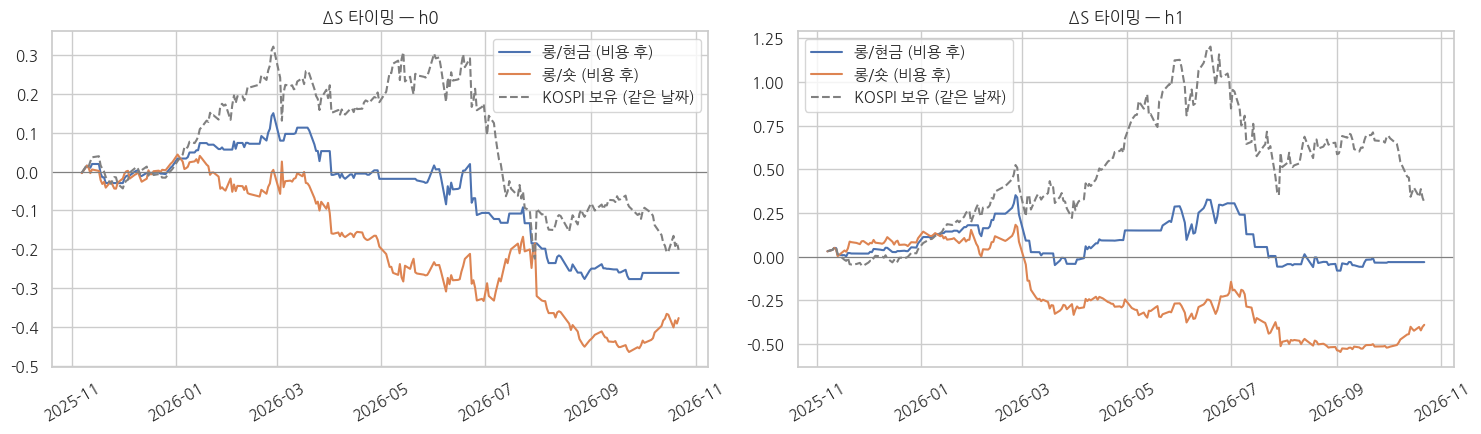

     전략  일수  노출일 비율  적중률  일평균(bp, 비용 전)  일평균(bp, 비용 후)  누적(%, 비용 후)  보유(%)
h0 롱/현금 231    0.51 0.52          -6.76         -11.82       -26.09 -20.14
 h0 롱/숏 231    1.00 0.51          -7.09         -17.09       -37.74 -20.14
h1 롱/현금 231    0.51 0.60           3.74           1.62        -3.20  31.13
 h1 롱/숏 231    1.00 0.50         -10.67         -14.89       -39.14  31.13

💡 h0는 매일 왕복 매매라 비용 영향이 큽니다. '보유'는 같은 날짜 구간의 KOSPI 단순 보유 수익률입니다.
💡 KOSPI가 크게 오른 구간이면 롱/현금 전략은 보유보다 뒤처지기 쉽습니다 — 적중률과 일평균을 함께 보세요.


In [ ]:
# === Part 4-4: 시장 타이밍 백테스트 (KOSPI 기준, ΔS 부호) ===
COST_BP = 5   # 편도 거래비용 가정 (bp) — 지수선물·ETF 수준을 가정, 필요하면 바꾸세요

def run_bt(signal, ret, mode, horizon, legs=1):
    """legs: 동시에 매매하는 종목 수 (페어는 2) — 비용에 곱함"""
    d = pd.concat([signal.rename('s'), ret.rename('r')], axis=1).dropna()
    pos = pd.Series(np.where(d['s'] > 0, 1.0, 0.0 if mode == 'long_flat' else -1.0), index=d.index)
    gross = pos * d['r']
    if horizon == 'h0':                       # 매일 시가 진입·종가 청산 → 포지션 있는 날 왕복
        cost = pos.abs() * 2 * COST_BP / 1e4 * legs
    else:                                     # 종가→종가 보유 → 포지션이 바뀔 때만
        cost = pos.diff().abs().fillna(pos.abs()) * COST_BP / 1e4 * legs
    return pd.DataFrame({'pos': pos, 'ret': d['r'], 'gross': gross, 'net': gross - cost})

def summarize(bt, name):
    inv = bt['pos'] != 0
    hit = (np.sign(bt.loc[inv, 'pos']) == np.sign(bt.loc[inv, 'ret'])).mean() if inv.any() else np.nan
    return {'전략': name, '일수': len(bt), '노출일 비율': inv.mean(), '적중률': hit,
            '일평균(bp, 비용 전)': bt['gross'].mean() * 1e4, '일평균(bp, 비용 후)': bt['net'].mean() * 1e4,
            '누적(%, 비용 후)': ((1 + bt['net']).prod() - 1) * 100,
            '보유(%)': ((1 + bt['ret']).prod() - 1) * 100}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
summary = []
for ax, h in zip(axes, ['h0', 'h1']):
    tg = f'KOSPI_{h}'
    for mode, label in [('long_flat', '롱/현금'), ('long_short', '롱/숏')]:
        bt = run_bt(sig['dS'], rets[tg], mode, h)
        summary.append(summarize(bt, f"{h} {label}"))
        ax.plot(bt.index, (1 + bt['net']).cumprod() - 1, label=f"{label} (비용 후)")
    ax.plot(bt.index, (1 + bt['ret']).cumprod() - 1, color='gray', linestyle='--', label='KOSPI 보유 (같은 날짜)')
    ax.set_title(f"ΔS 타이밍 — {h}", fontsize=12, fontweight='bold')
    ax.axhline(0, color='gray', linewidth=0.8)
    ax.legend(); ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

print(pd.DataFrame(summary).round(2).to_string(index=False))
print("\n💡 h0는 매일 왕복 매매라 비용 영향이 큽니다. '보유'는 같은 날짜 구간의 KOSPI 단순 보유 수익률입니다.")
print("💡 KOSPI가 크게 오른 구간이면 롱/현금 전략은 보유보다 뒤처지기 쉽습니다 — 적중률과 일평균을 함께 보세요.")

=== 상대 감성(삼성 − 하닉) vs 다음 거래일 수익률 차이(삼성 − 하닉) ===
신호        대상  Pearson  Spearman     t값  일수
 D spread_h0    0.034     0.018  0.497 218
 D spread_h1    0.062     0.088  0.910 218
dD spread_h0   -0.047    -0.081 -0.671 208
dD spread_h1    0.024     0.062  0.339 208


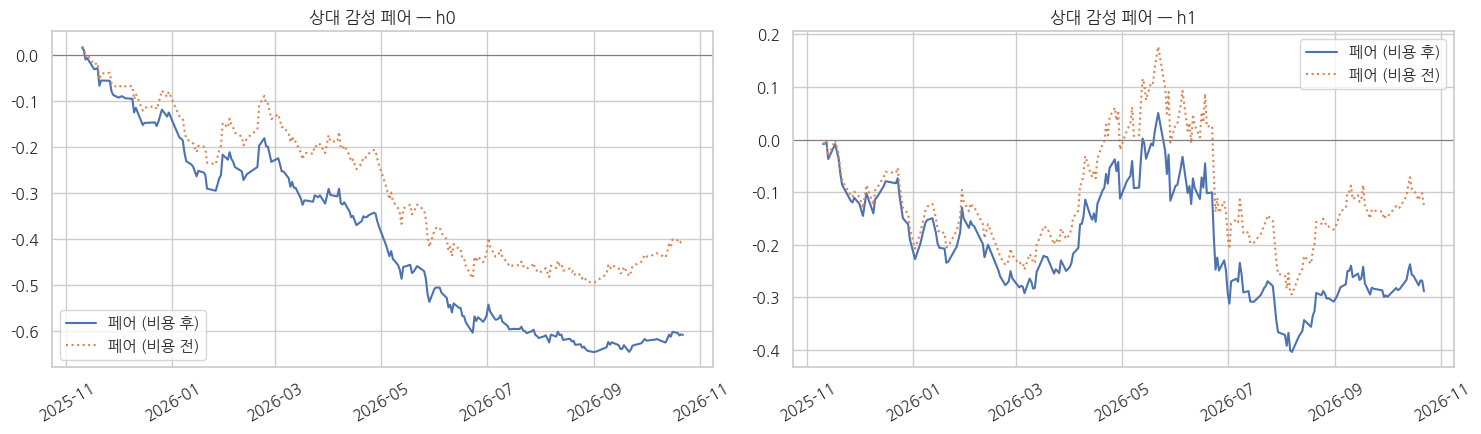

   전략  일수  노출일 비율  적중률  일평균(bp, 비용 전)  일평균(bp, 비용 후)  누적(%, 비용 후)
페어 h0 208     1.0 0.46         -22.48         -42.48       -60.92
페어 h1 208     1.0 0.52          -2.11         -11.87       -28.84

💡 두 종목 모두 뉴스가 있는 날만 포지션을 잡습니다. 비용은 두 종목 매매라 2배로 계산했습니다.


In [ ]:
# === Part 4-5: 페어 — 삼성전자 vs SK하이닉스 상대 감성 ===
pair = pd.DataFrame({'D': sig['D'], 'dD': sig['dD'],
                     'spread_h0': rets['삼성전자_h0'] - rets['SK하이닉스_h0'],
                     'spread_h1': rets['삼성전자_h1'] - rets['SK하이닉스_h1']})

print("=== 상대 감성(삼성 − 하닉) vs 다음 거래일 수익률 차이(삼성 − 하닉) ===")
rows = []
for s in ['D', 'dD']:
    for tg in ['spread_h0', 'spread_h1']:
        r, rho, t, n = corr_row(pair[s], pair[tg])
        rows.append({'신호': s, '대상': tg, 'Pearson': r, 'Spearman': rho, 't값': t, '일수': n})
print(pd.DataFrame(rows).round(3).to_string(index=False))

# 백테스트: dD > 0 → 삼성 매수·하닉 매도, dD < 0 → 반대 (두 종목 모두 뉴스가 있는 날만)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
psum = []
for ax, h in zip(axes, ['h0', 'h1']):
    bt = run_bt(pair['dD'], pair[f'spread_{h}'], 'long_short', h, legs=2)
    s = summarize(bt, f"페어 {h}")
    s.pop('보유(%)')
    psum.append(s)
    ax.plot(bt.index, (1 + bt['net']).cumprod() - 1, label='페어 (비용 후)')
    ax.plot(bt.index, (1 + bt['gross']).cumprod() - 1, linestyle=':', label='페어 (비용 전)')
    ax.axhline(0, color='gray', linewidth=0.8)
    ax.set_title(f"상대 감성 페어 — {h}", fontsize=12, fontweight='bold')
    ax.legend(); ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

print(pd.DataFrame(psum).round(2).to_string(index=False))
print("\n💡 두 종목 모두 뉴스가 있는 날만 포지션을 잡습니다. 비용은 두 종목 매매라 2배로 계산했습니다.")